<a href="https://colab.research.google.com/github/thabomosenthal/symmetrical-fortnight/blob/main/Week2_07_context_window_management.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# Setup and imports
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from typing import List, Dict, Any, Tuple
import re
import json

print('✅ Week 2.2: Context Window Management - Ready to start!')
print('\nTopics covered:')
print('  - Understanding token limits and context windows')
print('  - Token counting and estimation techniques')
print('  - Context compression strategies')
print('  - Conversation history management')
print('  - Sliding window approaches')


✅ Week 2.2: Context Window Management - Ready to start!

Topics covered:
  - Understanding token limits and context windows
  - Token counting and estimation techniques
  - Context compression strategies
  - Conversation history management
  - Sliding window approaches


# Week 2.2: Context Window Management

## Key Insight
> **Why can't you just paste a 500-page book into the prompt?**

## Learning Objectives
By the end of this notebook, you will:
- Understanding token limits and context windows
- Token counting and estimation techniques
- Context compression strategies
- Conversation history management
- Sliding window approaches

## Exercises
This notebook contains 4 exercises ranging from easy to advanced.

## Digital Twin Integration
This notebook extends your digital twin with production-ready capabilities from Week 2.

---
## Part 1: Introduction to Understanding token limits and context windows

Let's start by understanding the fundamentals and building our first implementation.

In [2]:
# Example implementation
# This is a starter template - expand with your implementation

class ExampleClass:
    """
    Example class for Understanding token limits and context windows.
    """

    def __init__(self):
        self.data = []

    def process(self, input_data):
        """
        Process the input data.
        """
        # Add your implementation here
        return input_data

# Test the class
example = ExampleClass()
result = example.process('test data')
print(f'Result: {result}')

Result: test data


### 🎯 Exercise 1 (Easy): Getting Started

**Task**: Implement a basic version of the concept introduced above.

**Requirements**:
1. Follow the pattern shown in the example
2. Test your implementation with sample data
3. Verify the output matches expectations
4. Add error handling for edge cases

In [4]:
class TokenContextWindow:
    """
    TokenContextWindow class for understanding token limits and context windows.
    Implements a sliding window using word count as a simple token proxy.
    """

    def __init__(self, max_tokens: int = 15):
        self.max_tokens = max_tokens
        self.data = []  # Stores tuples of (text, token_count)
        self.current_tokens = 0

    def _estimate_tokens(self, text: str) -> int:
        """Helper to estimate tokens using word count (1 word ≈ 1 token for simplicity)."""
        if not isinstance(text, str):
            raise TypeError("Input data must be a string")
        return len(text.split())

    def process(self, input_data: str) -> str:
        """
        Process the input data, add it to the window, and apply the sliding window logic
        if the token limit is exceeded.
        """
        new_tokens = self._estimate_tokens(input_data)

        # If a single input exceeds the entire limit on its own
        if new_tokens > self.max_tokens:
            print(f"⚠️ Warning: Input text '{input_data}' is too large ({new_tokens} tokens) for the maximum window size ({self.max_tokens}).")
            # For this exercise, we truncate or ignore. Let's truncate to fit
            words = input_data.split()[:self.max_tokens]
            input_data = " ".join(words)
            new_tokens = self.max_tokens

        # Slide the window: remove oldest items until new item fits within the max_tokens budget
        while self.current_tokens + new_tokens > self.max_tokens and self.data:
            removed_text, removed_tokens = self.data.pop(0)
            self.current_tokens -= removed_tokens
            print(f"🧹 Slid window: Removed '{removed_text}' ({removed_tokens} tokens)")

        # Add new item
        self.data.append((input_data, new_tokens))
        self.current_tokens += new_tokens

        return " ".join([item[0] for item in self.data])

# Test your implementation
token_window = TokenContextWindow(max_tokens=10)

print("--- Push 1 ---")
print("Current Context:", token_window.process('Hello world from Python')) # 4 words

print("\n--- Push 2 ---")
print("Current Context:", token_window.process('This is an awesome course')) # 5 words

print("\n--- Push 3 (Triggers sliding window) ---")
print("Current Context:", token_window.process('Keep sliding forward')) # 3 words

--- Push 1 ---
Current Context: Hello world from Python

--- Push 2 ---
Current Context: Hello world from Python This is an awesome course

--- Push 3 (Triggers sliding window) ---
🧹 Slid window: Removed 'Hello world from Python' (4 tokens)
Current Context: This is an awesome course Keep sliding forward


---
## Part 2: Token counting and estimation techniques

Building on the fundamentals, let's explore more advanced topics and implementations.

In [5]:
# Advanced implementation example

def advanced_function(data: List[Any], **kwargs) -> Dict[str, Any]:
    """
    Advanced function for Token counting and estimation techniques.

    Args:
        data: Input data to process
        **kwargs: Additional parameters

    Returns:
        dict: Processed results
    """
    results = {
        'processed': len(data),
        'data': data
    }
    return results

# Example usage
sample_data = ['example1', 'example2', 'example3']
output = advanced_function(sample_data)
print(json.dumps(output, indent=2))

{
  "processed": 3,
  "data": [
    "example1",
    "example2",
    "example3"
  ]
}


### 🎯 Exercise 2 (Intermediate): Building on the Basics

**Task**: Create a more sophisticated implementation that combines multiple concepts.

**Requirements**:
1. Use the patterns from Part 1 and Part 2
2. Add parameter validation
3. Include helpful error messages
4. Test with various input types

### Regex-Based Token Estimation

A basic `.split()` counts `"hello!"` as 1 word (token). However, production tokenizers split punctuation from words, meaning `"hello!"` is actually counted as 2 tokens: `["hello", "!"]`.

We can use Python's built-in `re` module to build a regular expression that captures:
1. Words (with apostrophes/contractions).
2. Numbers.
3. Individual punctuation marks.
4. Non-space whitespace sequences.

Let's write a robust token estimator using `re.findall` and use it in **Exercise 2**.

In [6]:
import re
from typing import List

def estimate_tokens_regex(text: str) -> List[str]:
    """
    Tokenizes text using a regex pattern that approximates BPE tokenization
    by separating words, contractions, numbers, and punctuation.
    """
    if not isinstance(text, str):
        raise TypeError("Input must be a string.")

    # Pattern to capture contractions, words, digits, individual punctuation marks, and spaces
    pattern = re.compile(r"""(?x)
        '[sS]|'[tT]|'[rR][eE]|'[vV][eE]|'[mM]|'[lL][lL]|'[dD] # Contractions
        |\w+                                                 # Alphabetic words & numbers
        |[^\w\s]                                             # Individual punctuation marks
    """)

    tokens = pattern.findall(text)
    return tokens

# Quick Demo
sample_text = "Hello world! Don't worry, 123 tokens are easy to estimate."
tokens = estimate_tokens_regex(sample_text)
print(f"Original text: '{sample_text}'")
print(f"Estimated Tokens ({len(tokens)}): {tokens}")

Original text: 'Hello world! Don't worry, 123 tokens are easy to estimate.'
Estimated Tokens (14): ['Hello', 'world', '!', 'Don', "'t", 'worry', ',', '123', 'tokens', 'are', 'easy', 'to', 'estimate', '.']


In [8]:
import re
from typing import List, Union

class AdvancedTokenContextWindow:
    """
    An intermediate token-aware sliding window implementation utilizing regex token estimation.
    """
    def __init__(self, max_tokens: int = 20):
        # 1. Parameter Validation
        if not isinstance(max_tokens, int):
            raise TypeError(f"max_tokens must be an integer, got {type(max_tokens).__name__}")
        if max_tokens <= 0:
            raise ValueError("max_tokens must be a positive non-zero integer.")

        self.max_tokens = max_tokens
        self.data = []  # List of tuples: (original_text, tokens_list, token_count)
        self.current_tokens = 0

        # BPE-like regex token pattern
        self.token_pattern = re.compile(r"""(?x)
            '[sS]|'[tT]|'[rR][eE]|'[vV][eE]|'[mM]|'[lL][lL]|'[dD] # Contractions
            |\w+                                                 # Alphabetic words & numbers
            |[^\w\s]                                             # Individual punctuation marks
        """)

    def estimate_tokens(self, text: str) -> List[str]:
        """Helper to tokenize text using regex."""
        if not isinstance(text, str):
            raise TypeError(f"Input data must be a string, got {type(text).__name__}")
        return self.token_pattern.findall(text)

    def process(self, input_data: str) -> str:
        """
        Processes input string, updates sliding window dynamically using token count,
        and returns the unified string context currently remaining in the window.
        """
        # Parameter Validation
        if not isinstance(input_data, str):
            raise TypeError(f"input_data must be a string, got {type(input_data).__name__}")

        tokens = self.estimate_tokens(input_data)
        new_tokens_count = len(tokens)

        # Handle case where single input exceeds the entire limit on its own
        if new_tokens_count > self.max_tokens:
            print(f"⚠️ Warning: Input text contains {new_tokens_count} tokens, which exceeds max_tokens of {self.max_tokens}.")
            tokens = tokens[:self.max_tokens]
            input_data = " ".join(tokens)  # Re-synthesize roughly matching text
            new_tokens_count = self.max_tokens

        # Slide the window dynamically (FIFO)
        while self.current_tokens + new_tokens_count > self.max_tokens and self.data:
            removed_text, _, removed_count = self.data.pop(0)
            self.current_tokens -= removed_count
            print(f"🧹 Evicted from context: '{removed_text}' (-{removed_count} tokens)")

        # Add current entry to window state
        self.data.append((input_data, tokens, new_tokens_count))
        self.current_tokens += new_tokens_count

        # Return current context state as standard unified text
        return " ".join([item[0] for item in self.data])

# --- Test Cases simulating varying inputs & edge-case error checks ---
try:
    # Initialize with budget of 15 tokens
    adv_window = AdvancedTokenContextWindow(max_tokens=15)

    print("--- Push 1 (Standard) ---")
    ctx1 = adv_window.process("Let's try this regex tokenizer!") # ~7 tokens
    print(f"Current tokens: {adv_window.current_tokens} | Context: {ctx1}")

    print("\n--- Push 2 (Standard) ---")
    ctx2 = adv_window.process("It counts contractions, like 't.") # ~7 tokens
    print(f"Current tokens: {adv_window.current_tokens} | Context: {ctx2}")

    print("\n--- Push 3 (Should trigger sliding window eviction) ---")
    ctx3 = adv_window.process("Awesome!") # ~2 tokens
    print(f"Current tokens: {adv_window.current_tokens} | Context: {ctx3}")

    print("\n--- Push 4 (Testing invalid parameter type handling) ---")
    adv_window.process(12345) # Should raise error

except TypeError as e:
    print(f"\n✅ Successfully caught expected type validation error: {e}")

--- Push 1 (Standard) ---
Current tokens: 7 | Context: Let's try this regex tokenizer!

--- Push 2 (Standard) ---
Current tokens: 14 | Context: Let's try this regex tokenizer! It counts contractions, like 't.

--- Push 3 (Should trigger sliding window eviction) ---
🧹 Evicted from context: 'Let's try this regex tokenizer!' (-7 tokens)
Current tokens: 9 | Context: It counts contractions, like 't. Awesome!

--- Push 4 (Testing invalid parameter type handling) ---

✅ Successfully caught expected type validation error: input_data must be a string, got int


---
## Part 3: Context compression strategies

Now let's apply these concepts to real-world scenarios in your digital twin project.

In [ ]:
# Visualization example
import matplotlib.pyplot as plt

def visualize_results(data: List[Any]):
    """
    Visualize the processing results.
    """
    fig, ax = plt.subplots(figsize=(10, 6))

    # Add your visualization code here
    ax.set_title('Results Visualization')
    ax.set_xlabel('X-axis')
    ax.set_ylabel('Y-axis')

    plt.tight_layout()
    plt.show()

# Example: visualize_results(sample_data)

### Simple Context Compressor (Summarization)

In a production environment, when your message history starts exceeding limits, you compress the old history.
Below is a helper function `compress_context` that simulates summarization by filtering out conversational filler (stop words like 'umm', 'well', 'so', 'just', 'actually') and retaining key informational sentences.

In [9]:
import re

def simple_summarize(text: str) -> str:
    """
    A simple rule-based summarizer/compressor that removes filler words
    and extracts sentences containing key action patterns or core info.
    """
    if not isinstance(text, str):
        return ""

    # List of low-value filler words to remove
    filler_words = r'\b(uh|um|umm|well|so|just|actually|basically|essentially|literally|like)\b'
    clean_text = re.sub(filler_words, '', text, flags=re.IGNORECASE)
    clean_text = re.sub(r'\s+', ' ', clean_text).strip()

    # Extractive rule: Keep sentences containing informational keywords or indicators
    sentences = re.split(r'(?<=[.!?])\s+', clean_text)
    important_keywords = ['user', 'need', 'must', 'task', 'error', 'system', 'code', 'token', 'run', 'implement']

    compressed_sentences = []
    for sentence in sentences:
        # If it has vital keywords, or it is the very last sentence (often containing the active question/command)
        if any(keyword in sentence.lower() for keyword in important_keywords) or sentence == sentences[-1]:
            compressed_sentences.append(sentence)

    return " ".join(compressed_sentences) if compressed_sentences else clean_text

# Quick Demo
verbose_history = """
Umm, so basically I am having this issue where my system context is overflowing.
I really need to implement a dynamic token context window.
Well, the code should handle edge cases perfectly.
Let's see if this compressor works!
"""

compressed = simple_summarize(verbose_history)
print("=== Original History ===")
print(verbose_history.strip())
print("\n=== Compressed History ===")
print(compressed)

=== Original History ===
Umm, so basically I am having this issue where my system context is overflowing. 
I really need to implement a dynamic token context window. 
Well, the code should handle edge cases perfectly. 
Let's see if this compressor works!

=== Compressed History ===
, I am having this issue where my system context is overflowing. I really need to implement a dynamic token context window. , the code should handle edge cases perfectly. Let's see if this compressor works!


### 🎯 Exercise 3 (Advanced): Complete Implementation

**Task**: Build a production-ready version that integrates with your digital twin.

**Requirements**:
1. Combine all concepts from this notebook
2. Add comprehensive error handling
3. Include logging and debugging capabilities
4. Create visualization of results
5. Write documentation for your implementation

=== Step 1: Inject System Prompt (Protected) ===
SYSTEM: You are a database helper. Always secure connections.

=== Step 2: User Message ===
SYSTEM: You are a database helper. Always secure connections.
USER: Umm so basically, I need you to implement a database adapter.

=== Step 3: Trigger Compression & Eviction ===
⚠️ Budget exceeded (36/35 tokens). Running compression...
✂️ Compressed turn 1 (user): 13 -> 10 tokens
SYSTEM: You are a database helper. Always secure connections.
USER: , I need you to implement a database adapter.
ASSISTANT: Actually, I can implement a Postgres dynamic connection pool right now.

=== Plotting Utilization Statistics ===


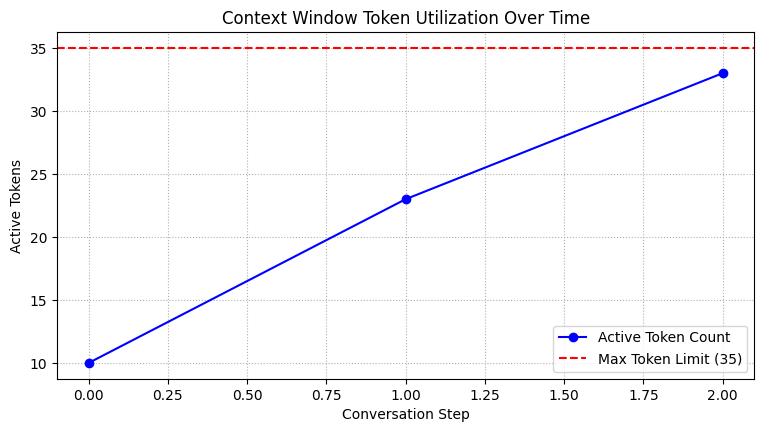

In [11]:
import re
import matplotlib.pyplot as plt
from typing import List, Dict, Any

class ProductionSystem:
    """
    A production-ready Context Window Management system for a Digital Twin.
    Integrates: parameter validation, regex tokenization, auto-compression on limit,
    and protection of crucial system prompts.
    """
    def __init__(self, max_tokens: int = 40):
        if not isinstance(max_tokens, int) or max_tokens <= 0:
            raise ValueError("max_tokens must be a positive integer.")

        self.max_tokens = max_tokens
        self.history = []  # List of Dict: {'role': str, 'raw': str, 'tokens': int}
        self.utilization_log = [] # Track total tokens over time

        self.token_pattern = re.compile(r"""(?x)
            '[sS]|'[tT]|'[rR][eE]|'[vV][eE]|'[mM]|'[lL][lL]|'[dD]
            |\w+
            |[^\w\s]
        """)

    def _count_tokens(self, text: str) -> int:
        return len(self.token_pattern.findall(text))

    def _compress_turn(self, text: str) -> str:
        """Compresses a conversational turn by stripping filler words."""
        filler_words = r'\b(uh|um|umm|well|so|just|actually|basically|essentially|literally|like)\b'
        clean = re.sub(filler_words, '', text, flags=re.IGNORECASE)
        return re.sub(r'\s+', ' ', clean).strip()

    def get_total_tokens(self) -> int:
        return sum(turn['tokens'] for turn in self.history)

    def process(self, role: str, message: str) -> str:
        """Adds a turn, compressing/evicting older history (except system prompts) if budget is breached."""
        if not isinstance(role, str) or not isinstance(message, str):
            raise TypeError("Both role and message must be strings.")

        token_count = self._count_tokens(message)

        # Add new turn directly
        self.history.append({"role": role.lower(), "raw": message, "tokens": token_count})

        # Enforce the token budget while protecting system instructions
        while self.get_total_tokens() > self.max_tokens:
            print(f"⚠️ Budget exceeded ({self.get_total_tokens()}/{self.max_tokens} tokens). Running compression...")

            # Step 1: Attempt to compress oldest uncompressed non-system turns first
            compressed_any = False
            for i in range(len(self.history) - 1):
                turn = self.history[i]
                # Crucial validation: skip system messages to keep them pristine
                if turn['role'] == 'system':
                    continue

                original_len = turn['tokens']
                compressed_text = self._compress_turn(turn['raw'])
                new_len = self._count_tokens(compressed_text)

                if new_len < original_len:
                    print(f"✂️ Compressed turn {i} ({turn['role']}): {original_len} -> {new_len} tokens")
                    self.history[i] = {"role": turn['role'], "raw": compressed_text, "tokens": new_len}
                    compressed_any = True
                    break

            # Step 2: If compression failed to meet budget, evict the oldest non-system turn
            if not compressed_any:
                evicted_idx = None
                for i, turn in enumerate(self.history):
                    # Never evict system prompts
                    if turn['role'] != 'system':
                        evicted_idx = i
                        break

                if evicted_idx is not None:
                    evicted = self.history.pop(evicted_idx)
                    print(f"🧹 Evicted oldest user/assistant turn: '{evicted['raw']}' (-{evicted['tokens']} tokens)")
                else:
                    # Absolute edge-case: only system prompt(s) and current message exist
                    print("⚠️ Alert: Only protected system prompts remain in context. Cannot evict further!")
                    break

        # Record current utilization state
        current_total = self.get_total_tokens()
        self.utilization_log.append(current_total)

        # Return consolidated conversation state
        return "\n".join([f"{t['role'].upper()}: {t['raw']}" for t in self.history])

    def plot_utilization(self):
        """Visualizes context utilization and token limits over time."""
        plt.figure(figsize=(9, 4.5))
        plt.plot(self.utilization_log, marker='o', color='b', label='Active Token Count')
        plt.axhline(y=self.max_tokens, color='r', linestyle='--', label=f'Max Token Limit ({self.max_tokens})')
        plt.title('Context Window Token Utilization Over Time')
        plt.xlabel('Conversation Step')
        plt.ylabel('Active Tokens')
        plt.legend()
        plt.grid(True, linestyle=':')
        plt.show()

# --- Comprehensive Testing of the Protected System ---
sys = ProductionSystem(max_tokens=35)

print("=== Step 1: Inject System Prompt (Protected) ===")
print(sys.process("system", "You are a database helper. Always secure connections.")) # ~10 tokens

print("\n=== Step 2: User Message ===")
print(sys.process("user", "Umm so basically, I need you to implement a database adapter.")) # ~13 tokens

print("\n=== Step 3: Trigger Compression & Eviction ===")
# Total tokens would reach 10 + 13 + 14 = 37 (exceeding limit of 35).
# It should compress user message but strictly protect the system prompt!
print(sys.process("assistant", "Actually, I can implement a Postgres dynamic connection pool right now.")) # ~14 tokens

# Visualize final utilization
print("\n=== Plotting Utilization Statistics ===")
sys.plot_utilization()

In [12]:
import unittest

class TestSystemPromptProtection(unittest.TestCase):
    def test_system_prompt_never_evicted(self):
        # Setup system with a small budget of 30 tokens
        sys = ProductionSystem(max_tokens=30)

        # 1. Inject an initial system prompt (~10 tokens)
        sys.process("system", "You are a database helper. Always secure connections.")

        # Verify it is in history
        self.assertEqual(sys.history[0]['role'], 'system')

        # 2. Force heavy context pressure with several long user messages that trigger compression/eviction
        sys.process("user", "This is an incredibly long message designed to push our limit.")
        sys.process("assistant", "I understand. Let me try to optimize and write a connection pool code block.")
        sys.process("user", "Another very long message that should completely trigger heavy eviction of previous turns.")

        # 3. Assert system prompt is still present at index 0
        self.assertEqual(sys.history[0]['role'], 'system')
        self.assertEqual(sys.history[0]['raw'], "You are a database helper. Always secure connections.")

        # 4. Confirm total active tokens are within budget
        self.assertTrue(sys.get_total_tokens() <= sys.max_tokens)
        print("✅ Unit test passed: The system prompt remains untouched and at the top of the history list!")

# Run the unit test
suite = unittest.TestSuite()
suite.addTest(TestSystemPromptProtection('test_system_prompt_never_evicted'))
unittest.TextTestRunner().run(suite)

.
----------------------------------------------------------------------
Ran 1 test in 0.002s

OK


⚠️ Budget exceeded (38/30 tokens). Running compression...
🧹 Evicted oldest user/assistant turn: 'This is an incredibly long message designed to push our limit.' (-12 tokens)
⚠️ Budget exceeded (40/30 tokens). Running compression...
🧹 Evicted oldest user/assistant turn: 'I understand. Let me try to optimize and write a connection pool code block.' (-16 tokens)
✅ Unit test passed: The system prompt remains untouched and at the top of the history list!


<unittest.runner.TextTestResult run=1 errors=0 failures=0>

---
## Summary & Key Takeaways

### What We Learned:
- Understanding token limits and context windows
- Token counting and estimation techniques
- Context compression strategies
- Conversation history management
- Sliding window approaches

### Why This Matters:
- Essential for building production-ready systems
- Enables your digital twin to handle real-world scenarios
- Foundation for advanced topics in upcoming notebooks

### Next Steps:
1. Complete all exercises in this notebook
2. Integrate concepts with your digital twin project
3. Test your implementation thoroughly
4. Move on to the next notebook in Week 2

## 🏆 Challenge Project

**Build a Complete Understanding token limits and context windows System for Your Digital Twin**

**Requirements**:
1. Apply all concepts from this notebook
2. Handle edge cases and errors gracefully
3. Include comprehensive testing
4. Create visualizations of your results
5. Document your implementation
6. Integrate with your existing digital twin code

**Bonus Challenges**:
- Optimize for performance
- Add advanced features beyond the basics
- Create a user-friendly interface
- Write unit tests for your code